# EDA: human / ai / fusion text detection

Data: `train.csv` and `test.csv` from the competition only. Seed fixed at 42.

In [52]:
import os
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import kagglehub
import language_tool_python
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy

SEED = 42
np.random.seed(SEED)

LABELS = ["human", "ai", "fusion"]
PALETTE = {"human": "#2a78d6", "ai": "#eb6834", "fusion": "#1baf7a"}

pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False})

In [53]:
DATA_DIR = Path(kagglehub.competition_download("ai-generated-text-detection-hw3-ucu-ai-2026"))

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print("train:", train.shape, "| test:", test.shape)
train.head()

train: (272352, 5) | test: (25000, 4)


,id,text,lang,domain,label
0,e7adad,Diego's Demons Return: Is the Football Legend Losing Control? Fans have been...,en-EN,cnn_news,ai
1,3bab63,"Herr Präsident! Meine Damen und Herren! Es wird Sie nicht völlig verwundern,...",de-DE,bundestag,human
2,4e6c1f,Frau Präsidentin! Liebe Kolleginnen und Kollegen! Dem Kollegen Kühn stimme i...,de-DE,bundestag,human
3,f92d07,[12/17/2002 9:40:16 PM | + racheal] shagging. I feel sick. I want to go thro...,en-EN,blog_authorship_corpus,human
4,6162f5,"IN THE COURT OF CASE NO. , Plaintiffs, v. , Defendant. RULING ON PENSION CLA...",en-EN,euro_court_cases,ai


## 1. Class balance

In [54]:
def class_table(df, by=None):
    """Counts and row shares (%) of each class, overall or per group."""
    groups = df[by] if by else pd.Series("all", index=df.index, name="")
    counts = pd.crosstab(groups, df["label"])[LABELS]
    shares = (100 * counts.div(counts.sum(axis=1), axis=0)).round(1).add_suffix(" %")
    return counts.assign(total=counts.sum(axis=1)).join(shares).sort_values("total", ascending=False)


class_table(train)

label,human,ai,fusion,total,human %,ai %,fusion %
,,,,,,,
all,66730,121940,83682,272352,24.5,44.8,30.7


In [55]:
display(class_table(train, "lang"))
display(class_table(train, "domain"))
pd.crosstab(train["domain"], train["lang"], margins=True)

label,human,ai,fusion,total,human %,ai %,fusion %
lang,,,,,,,
en-EN,52220,101603,65758,219581,23.8,46.3,29.9
de-DE,14510,20337,17924,52771,27.5,38.5,34.0


label,human,ai,fusion,total,human %,ai %,fusion %
domain,,,,,,,
student_essays,12506,21583,20017,54106,23.1,39.9,37.0
bundestag,14479,19977,17887,52343,27.7,38.2,34.2
cnn_news,13395,19488,11402,44285,30.2,44.0,25.7
blog_authorship_corpus,12466,15684,12397,40547,30.7,38.7,30.6
house_of_commons,6953,15298,9608,31859,21.8,48.0,30.2
euro_court_cases,6277,11141,10160,27578,22.8,40.4,36.8
arxiv_papers,407,12050,1833,14290,2.8,84.3,12.8
gutenberg,247,6719,378,7344,3.4,91.5,5.1


lang,de-DE,en-EN,All
domain,,,
arxiv_papers,0,14290,14290
blog_authorship_corpus,0,40547,40547
bundestag,52343,0,52343
cnn_news,0,44285,44285
euro_court_cases,0,27578,27578
gutenberg,428,6916,7344
house_of_commons,0,31859,31859
student_essays,0,54106,54106
All,52771,219581,272352


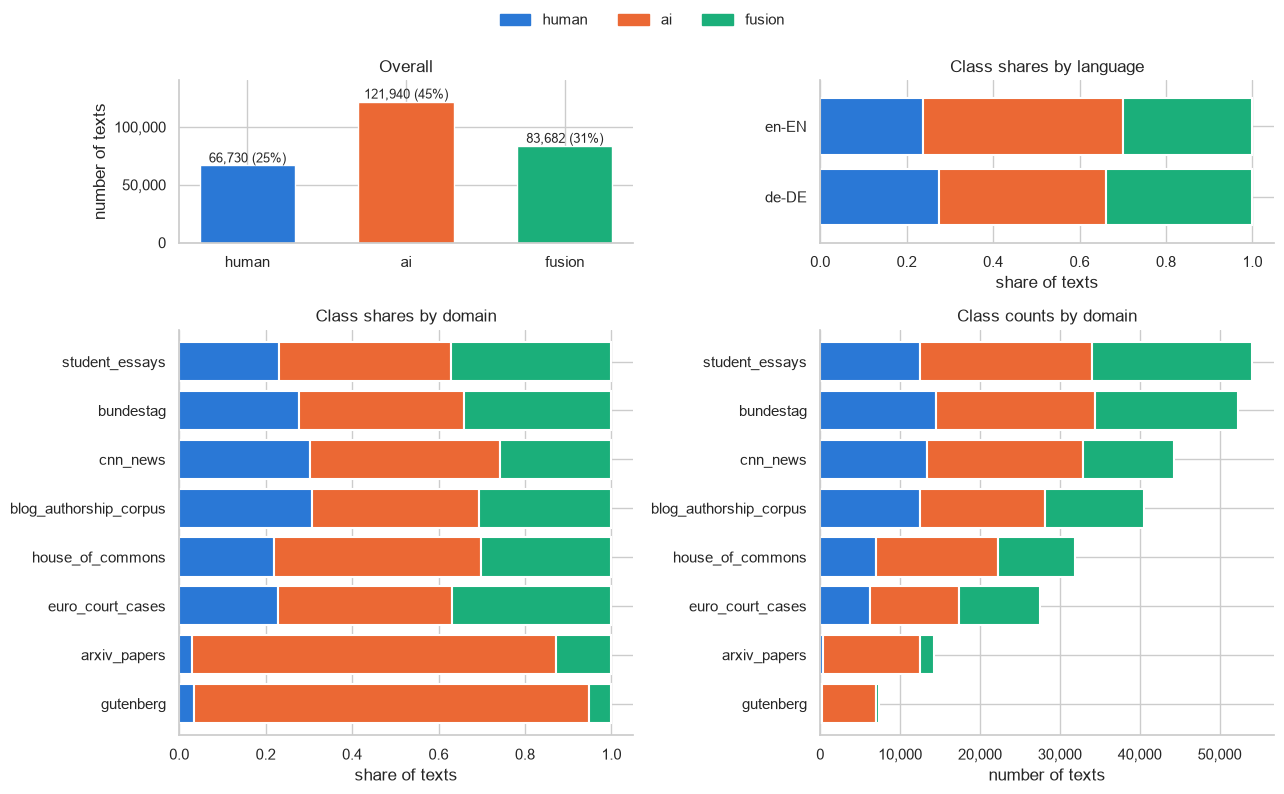

In [56]:
def plot_shares(df, by, ax, normalize=True):
    """Stacked horizontal bars of class shares (or counts) per group, largest group on top."""
    table = pd.crosstab(df[by], df["label"], normalize="index" if normalize else False)[LABELS]
    table = table.loc[df[by].value_counts().index[::-1]]
    table.plot.barh(stacked=True, ax=ax, color=[PALETTE[l] for l in LABELS],
                    edgecolor="white", linewidth=1.5, width=0.8, legend=False)
    ax.set(ylabel="", xlabel="share of texts" if normalize else "number of texts")


THOUSANDS = plt.FuncFormatter(lambda x, _: f"{x:,.0f}")
fig, axes = plt.subplots(2, 2, figsize=(13, 8), gridspec_kw={"height_ratios": [1, 2.5]})

counts = train["label"].value_counts()[LABELS]
axes[0, 0].bar(LABELS, counts, color=[PALETTE[l] for l in LABELS], width=0.6)
for i, n in enumerate(counts):
    axes[0, 0].text(i, n, f"{n:,} ({n / len(train):.0%})", ha="center", va="bottom", fontsize=9)
axes[0, 0].set(title="Overall", ylabel="number of texts")
axes[0, 0].yaxis.set_major_formatter(THOUSANDS)
axes[0, 0].margins(y=0.15)

plot_shares(train, "lang", axes[0, 1])
axes[0, 1].set_title("Class shares by language")
plot_shares(train, "domain", axes[1, 0])
axes[1, 0].set_title("Class shares by domain")
plot_shares(train, "domain", axes[1, 1], normalize=False)
axes[1, 1].set_title("Class counts by domain")
axes[1, 1].xaxis.set_major_formatter(THOUSANDS)

handles = [plt.Rectangle((0, 0), 1, 1, color=PALETTE[l]) for l in LABELS]
fig.legend(handles, LABELS, loc="upper center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Notes: class balance**
- **Imbalanced:** ai 44.8% · fusion 30.7% · human 24.5%.
- **Language ≈ domain:** German is only `bundestag` (+ 428 `gutenberg` texts); all other domains are English only. Language and domain effects cannot be separated: "German" results are mostly `bundestag` results.
- **German has more human / fusion** than English: 27.5% / 34.0% vs 23.8% / 29.9%.
- **Two almost pure-ai domains:** `arxiv_papers` 84% ai (407 human texts), `gutenberg` 92% ai (247 human texts). There, the domain alone is a strong prior.
- **The other six domains look alike:** fusion 26–37%, human 22–31%.

**→ For modelling**
- Macro-F1 weighs all three classes equally, so accuracy is misleading. Try class weights / threshold tuning.
- Report per-domain F1 to check that the model learns more than the domain.
- Validation split: stratify by label × language and keep human–fusion twins together (section 5).

## 2. Text lengths

In [57]:
for df in (train, test):
    df["n_chars"] = df["text"].str.len()
    df["n_words"] = df["text"].str.count(r"\S+")


def length_table(df, by, col="n_words"):
    """Median and tail quantiles of a length column per group."""
    q = df.groupby(by)[col].quantile([0.05, 0.5, 0.9, 0.99]).unstack()
    q.columns = ["p5", "median", "p90", "p99"]
    return q.round(0).astype(int)


display(length_table(train, ["lang", "label"]))
length_table(train, ["domain", "label"])

p5  median   p90   p99
lang  label                          
de-DE ai       84     430   648   833
      fusion  255     584   910  1448
      human    93     584   925  1495
en-EN ai       56     481   908  1346
      fusion   68     389  1298  2797
      human    51     439  1189  2619

p5  median   p90   p99
domain                 label                           
arxiv_papers           ai        90     824  1183  1707
                       fusion  1120    2344  2887  2988
                       human   1157    2382  2887  2981
blog_authorship_corpus ai        26     129   448   904
                       fusion    33     128   438  1120
                       human     27     137   502  1265
bundestag              ai        85     429   646   830
                       fusion   256     584   909  1428
                       human     93     585   924  1474
cnn_news               ai       226     530   880  1161
                       fusion   200     501   966  1461
                       human    250     627  1148  1656
euro_court_cases       ai       151     550   912  1234
                       fusion   195     764  2068  2837
                       human    211     854  2198  2898
gutenberg              ai       218     696  1116  2003
                       fusion    84    1538  2752  2949
                       human     43    1131  2670  2984
house_of_commons       ai        73     547   858  1212
                       fusion   116     509  1867  2898
                       human     95     554  1503  2735
student_essays         ai       178     371   607   889
                       fusion   158     343   581   862
                       human    184     388   682   999

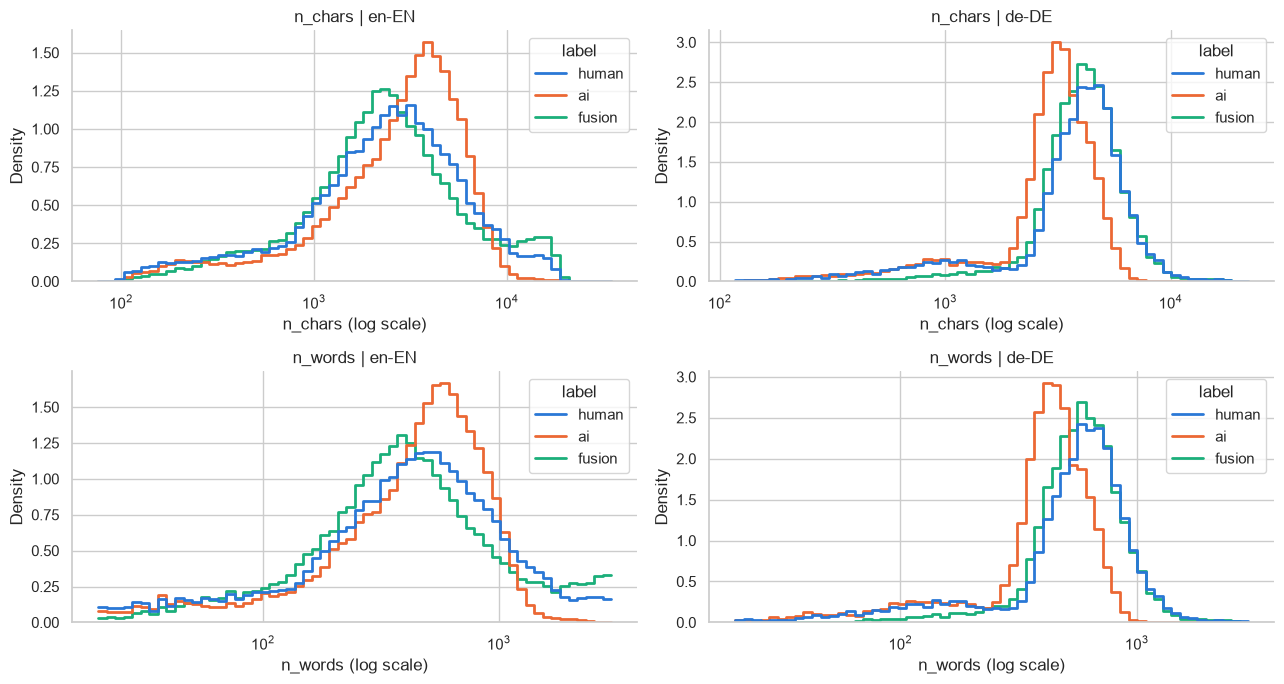

In [58]:
langs = train["lang"].value_counts().index
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for j, lang in enumerate(langs):
    for i, col in enumerate(["n_chars", "n_words"]):
        sns.histplot(data=train[train["lang"] == lang], x=col, hue="label", hue_order=LABELS, palette=PALETTE,
                     log_scale=True, element="step", fill=False, stat="density", common_norm=False,
                     bins=60, linewidth=2, ax=axes[i, j])
        axes[i, j].set(title=f"{col} | {lang}", xlabel=f"{col} (log scale)")
fig.tight_layout()
plt.show()

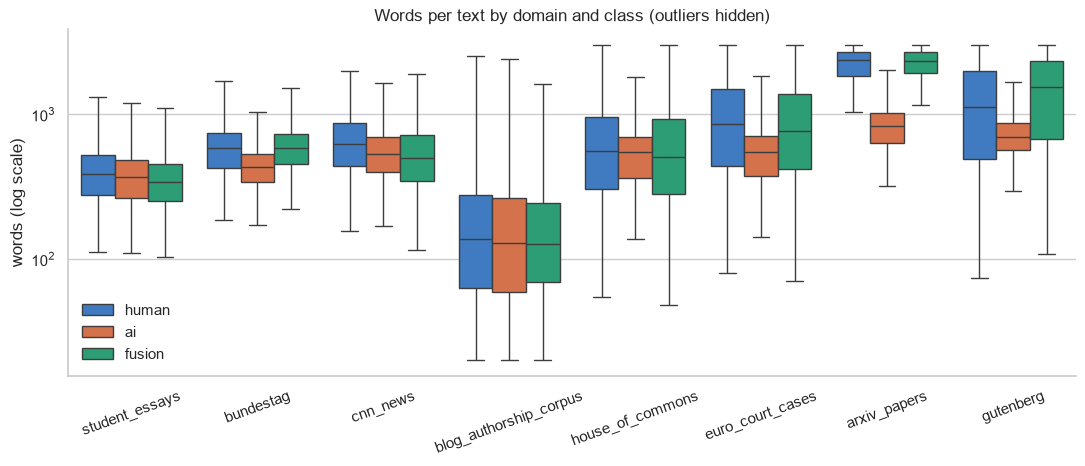

In [59]:
fig, ax = plt.subplots(figsize=(13, 4.5))
sns.boxplot(data=train, x="domain", y="n_words", hue="label", hue_order=LABELS, palette=PALETTE,
            order=train["domain"].value_counts().index, showfliers=False, log_scale=True, ax=ax)
ax.set(title="Words per text by domain and class (outliers hidden)", xlabel="", ylabel="words (log scale)")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="", frameon=False)
plt.show()

In [9]:
# Texts seem to be cut at 3,000 words: how many get close to that cap?
CAP = 2_900
near_cap = train["n_words"] >= CAP
pd.DataFrame({
    "max words": [*train.groupby("label")["n_words"].max()[LABELS], test["n_words"].max()],
    f"% >= {CAP:,} words": [*(100 * near_cap.groupby(train["label"]).mean()[LABELS]).round(2),
                           round(100 * (test["n_words"] >= CAP).mean(), 2)],
}, index=[*LABELS, "test"])

,max words,"% >= 2,900 words"
human,2998,0.20
ai,2996,0.01
fusion,3000,0.40
test,3000,0.15


**Notes: word / character lengths**

| median words | human | fusion | ai |
|---|---|---|---|
| English | 439 | 389 | 481 |
| German | 584 | 584 | 430 |

- **Opposite patterns by language:** in English ai is the longest class at the median; in German it is clearly the shortest. Human and fusion have long right tails.
- **Domain matters more than class:** in `arxiv_papers` ai has a median of 824 words vs ~2,350 for human / fusion; `gutenberg` (696 vs 1,131 / 1,538) and `euro_court_cases` (550 vs 854 / 764) show the same pattern.
- **Overlap elsewhere:** in `student_essays`, `blog_authorship_corpus` and `cnn_news` the classes overlap. Blogs are very short (median ~130 words).
- **Human ≈ fusion** in most domains.
- **Hard cap at ~3,000 words** in train and test (a preprocessing artefact); it affects ≤ 0.4% of texts.

**→ For modelling**
- Length nearly separates ai in `arxiv_papers` / `gutenberg` / `euro_court_cases`: a useful feature, but also a shortcut risk.
- Length will not separate fusion from human.

### Subword tokens (XLM-R tokenizer)
Counted on a fixed stratified 20k sample. This decides `max_len` and whether long texts need chunking.

In [60]:
os.environ["TRANSFORMERS_VERBOSITY"] = "error"  # hide "sequence longer than max length" warnings
from transformers import AutoTokenizer

TOKENIZER_NAME = "xlm-roberta-base"
TOKEN_SAMPLE = 20_000
MAX_LEN = 512
WINDOW = MAX_LEN - 2  # room for <s> and </s>

tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_NAME)

# Fixed subsample that keeps label x language proportions.
tok_sample = train.groupby(["label", "lang"], group_keys=False).sample(
    frac=TOKEN_SAMPLE / len(train), random_state=SEED).copy()
tok_sample["n_tokens"] = [len(ids) for ids in tokenizer(tok_sample["text"].tolist(), add_special_tokens=False)["input_ids"]]
tok_sample["tokens_per_word"] = tok_sample["n_tokens"] / tok_sample["n_words"]
tok_sample["over_max_len"] = tok_sample["n_tokens"] > WINDOW
tok_sample["n_chunks"] = np.ceil(tok_sample["n_tokens"] / WINDOW)
print(f"tokenized {len(tok_sample):,} texts")

tokenized 20,000 texts


In [61]:
def token_table(df, by):
    """Token length stats and how many texts do not fit into one MAX_LEN window."""
    g = df.groupby(by)
    return pd.DataFrame({
        "median tokens": g["n_tokens"].median(),
        "p90 tokens": g["n_tokens"].quantile(0.9),
        "tokens per word": g["tokens_per_word"].median().round(2),
        f"% > {MAX_LEN}": (100 * g["over_max_len"].mean()).round(1),
        "mean chunks": g["n_chunks"].mean().round(2),
    })


display(token_table(tok_sample, ["lang", "label"]))
token_table(tok_sample, "domain").sort_values(f"% > {MAX_LEN}", ascending=False)

median tokens  p90 tokens  tokens per word  % > 512  mean chunks
lang  label                                                                   
de-DE ai              642.0       950.8             1.50     73.9         1.79
      fusion          886.0      1351.0             1.50     91.8         2.33
      human           891.0      1419.0             1.52     83.2         2.30
en-EN ai              715.0      1400.0             1.47     66.9         2.02
      fusion          525.0      1751.2             1.36     51.5         2.08
      human           597.0      1626.0             1.36     57.4         2.08

,median tokens,p90 tokens,tokens per word,% > 512,mean chunks
domain,,,,,
gutenberg,1106.0,1822.6,1.56,94.6,2.87
arxiv_papers,1483.0,3779.4,1.65,91.8,3.97
bundestag,771.0,1235.0,1.51,82.5,2.11
cnn_news,811.0,1381.0,1.45,82.5,2.20
euro_court_cases,928.0,2490.2,1.43,80.0,2.79
house_of_commons,752.0,1558.4,1.34,71.0,2.21
student_essays,481.0,816.0,1.32,44.6,1.48
blog_authorship_corpus,193.0,697.0,1.45,16.6,1.23


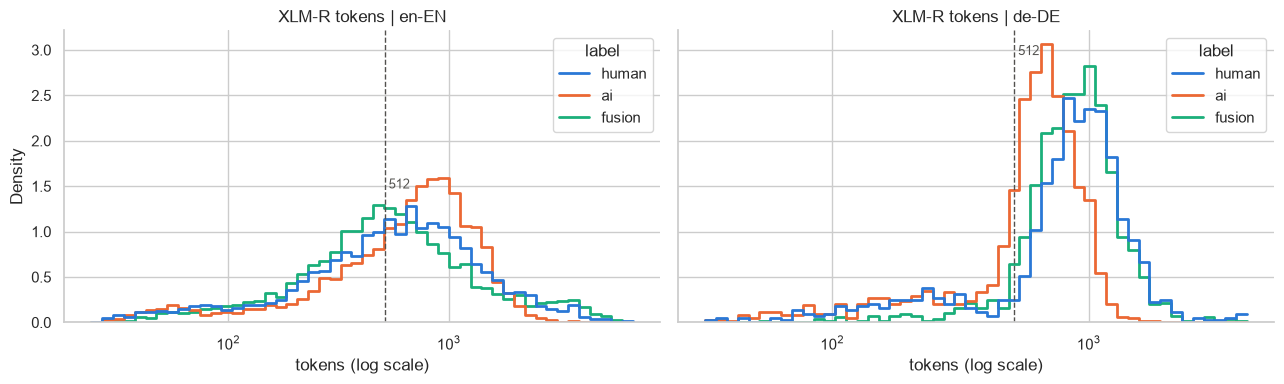

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, lang in zip(axes, langs):
    sns.histplot(data=tok_sample[tok_sample["lang"] == lang], x="n_tokens", hue="label", hue_order=LABELS,
                 palette=PALETTE, log_scale=True, element="step", fill=False, stat="density",
                 common_norm=False, bins=50, linewidth=2, ax=ax)
    ax.axvline(MAX_LEN, color="#52514e", linestyle="--", linewidth=1)
    ax.text(MAX_LEN, ax.get_ylim()[1] * 0.95, f" {MAX_LEN}", color="#52514e", fontsize=9, va="top")
    ax.set(title=f"XLM-R tokens | {lang}", xlabel="tokens (log scale)")
fig.tight_layout()
plt.show()

**Notes: token lengths** (fixed 20k stratified sample, seed 42)

| % texts > 512 tokens | human | fusion | ai |
|---|---|---|---|
| English | 57.4 | 51.5 | 66.9 |
| German | 83.2 | 91.8 | 73.9 |

- **Most texts do not fit one 512-token window.** German fusion is the longest group (median 886 tokens).
- **Windows needed per text:** ~2 on average; `arxiv_papers` ~4, `gutenberg` ~2.9, blogs ~1.2.
- **German costs more tokens per word:** ~1.50 vs 1.36–1.47 for English.

**→ For modelling**
- Truncating to 512 tokens keeps only the first ~350 words. Compare head-only, head + tail, and chunking with averaged chunk predictions.
- This matters most for fusion: section 5 shows that fusion texts start with copied human text.

## 3. Examples of each class
One random text per class from the same domain, so the classes are easier to compare. Each text shows its first and last 200 characters.

In [63]:
import re


def snippet(text, n=200):
    """Start and end of a text with whitespace collapsed, so long texts stay short."""
    text = re.sub(r"\s+", " ", str(text)).strip()
    return text if len(text) <= 2 * n else f"{text[:n]} [...] {text[-n:]}"


def show_examples(df, domain, per_class=1, n=200):
    """Prints random examples of each class from one domain (start + end of each text)."""
    sub = df[df["domain"] == domain]
    print(f"########## {domain} ##########")
    for label in LABELS:
        for _, row in sub[sub["label"] == label].sample(per_class, random_state=SEED).iterrows():
            print(f"--- {label.upper()} | {row['lang']} | {row['n_words']} words")
            print(snippet(row["text"], n), "\n")


for domain in ["cnn_news", "student_essays", "bundestag"]:
    show_examples(train, domain)

########## cnn_news ##########
--- HUMAN | en-EN | 218 words
New York (CNN) No "potential human remains" have been found in the Manhattan location where a 9/11 aircraft part was recently discovered, New York's chief medical examiner said Wednesday. The announce [...] ome of the personnel there responded to the attack. "It's a piece of history and we tried to preserve it as best we could," said Police Deputy Chief William Aubry. "It brought back a lot of memories." 

--- AI | en-EN | 534 words
French forces pressed their offensive against Islamist insurgents in northern Mali, recapturing the key city of Gao and pushing towards Timbuktu on Monday, marking a significant shift in the battle fo [...] nd sustained political will. As the conflict unfolds, the international community continues to watch closely, hoping for a peaceful resolution that brings stability and security to the people of Mali. 

--- FUSION | en-EN | 454 words
By . Jennifer Newton . Americans are becoming increasingly al

**Notes: examples** (one text per class and domain: impressions only, checked with numbers in sections 4–5)
- **Human:** source artefacts and small errors: `New York (CNN)`, missing apostrophes and lowercase "i" (`theyre`, `i think`), very short Bundestag interjections (46 words).
- **AI:** polished and generic: headline-style titles (`Breaking Free from the Asphalt Chains: ...`), rare words (`ubiquitous`, `perpetual`), big closing calls (`Let's embark on this journey together ...`, `Lassen Sie uns gemeinsam die Weichen ... stellen!`). The AI Bundestag speech starts with `...`.
- **Fusion:** mixes both. The CNN fusion opens with a scraping artefact like human news (`By . Jennifer Newton .`) but ends with a generic AI-style sentence (`These factors combine to create a dangerous cycle ...`). The student-essay fusion still has a human typo near the end (`isnt`).

**→ For modelling**
- Do not clean away artefacts like `By .`, `(CNN)`, typos or `...`: they are probably useful signals (but check they are not just domain markers).

## 4. What makes fusion different? (stylometry)
Style statistics on a fixed stratified 30k sample (label × language, seed 42), computed from spaCy parses (`en_core_web_sm` / `de_core_news_sm`): words = tokens that are not punctuation or whitespace, sentences = spaCy sentence boundaries, POS = Universal POS tags (same tag set in both languages). TTR = type-token ratio on the first 200 words, so text length does not bias it (NaN for shorter texts). Error rates from LanguageTool (local server) on a 10k subsample.

In [64]:
SPACY_MODELS = {"en-EN": "en_core_web_sm", "de-DE": "de_core_news_sm"}
N_PROCESS = 6

# NER and lemmas are not used below; disabling them makes parsing ~1.6x faster.
nlps = {lang: spacy.load(name, disable=["ner", "lemmatizer"]) for lang, name in SPACY_MODELS.items()}
{lang: nlp.pipe_names for lang, nlp in nlps.items()}

{'en-EN': ['tok2vec', 'tagger', 'parser', 'attribute_ruler'],
 'de-DE': ['tok2vec', 'tagger', 'morphologizer', 'parser', 'attribute_ruler']}

In [65]:
STYLE_SAMPLE = 30_000
TTR_WINDOW = 200
POS_TAGS = ["NOUN", "PROPN", "VERB", "ADJ", "ADV", "PRON", "DET"]
# No text contains a newline or tab (whitespace was normalised in the dataset), so no layout features.


def sentence_depth(sent):
    """Depth of the dependency tree of one sentence (root = 0): a measure of syntactic nesting."""
    return max(len(list(t.ancestors)) for t in sent)


def style_features(doc):
    """Per-text style statistics from a spaCy Doc."""
    words = [t for t in doc if not (t.is_punct or t.is_space)]
    n_words = max(len(words), 1)
    sent_lens = [sum(not (t.is_punct or t.is_space) for t in s) for s in doc.sents]
    pos = Counter(t.pos_ for t in words)
    return {
        "avg_word_len": np.mean([len(t) for t in words if t.is_alpha] or [np.nan]),
        "sent_len_mean": np.mean(sent_lens),
        "sent_len_std": np.std(sent_lens),  # "burstiness": how much sentence length varies
        "parse_depth": np.mean([sentence_depth(s) for s in doc.sents]),
        "ttr": len({t.lower_ for t in words[:TTR_WINDOW]}) / TTR_WINDOW if n_words >= TTR_WINDOW else np.nan,
        "stopword_ratio": sum(t.is_stop for t in words) / n_words,
        "punct_per_100w": 100 * sum(t.is_punct for t in doc) / n_words,
        "comma_per_100w": 100 * sum(t.text == "," for t in doc) / n_words,
        "num_per_100w": 100 * sum(t.like_num for t in words) / n_words,
        "upper_word_ratio": sum(t.is_upper for t in words) / n_words,  # ALL-CAPS words
        **{f"{tag.lower()}_ratio": pos[tag] / n_words for tag in POS_TAGS},
    }


# Fixed subsample that keeps label x language proportions.
style_df = train.groupby(["label", "lang"], group_keys=False).sample(
    frac=STYLE_SAMPLE / len(train), random_state=SEED)

rows = {}
for lang, part in style_df.groupby("lang"):
    docs = nlps[lang].pipe(part["text"], batch_size=64, n_process=N_PROCESS)
    rows |= {idx: style_features(doc) for idx, doc in zip(part.index, docs)}

style = pd.DataFrame.from_dict(rows, orient="index").loc[style_df.index]
FEATURES = list(style.columns)
style = style.join(style_df[["label", "lang", "domain"]])
print(f"{len(style):,} texts, {len(FEATURES)} spaCy features")

29,999 texts, 17 spaCy features


In [66]:
# Error counts with LanguageTool (local Java server, one per language). Slower than spaCy, so a 10k subsample.
ERROR_SAMPLE = 10_000
LT_LANGS = {"en-EN": "en-US", "de-DE": "de-DE"}
LT_THREADS = 8  # the local server handles parallel requests
ERROR_CATEGORIES = {"TYPOS": "spelling", "GRAMMAR": "grammar", "PUNCTUATION": "punct_error"}

error_df = style_df.groupby(["label", "lang"], group_keys=False).sample(
    frac=ERROR_SAMPLE / len(style_df), random_state=SEED)

parts = []
for lang, part in error_df.groupby("lang"):
    with language_tool_python.LanguageTool(LT_LANGS[lang]) as tool, ThreadPoolExecutor(LT_THREADS) as pool:
        matches = list(pool.map(tool.check, part["text"]))
    parts.append(pd.DataFrame([Counter(m.category for m in ms) for ms in matches], index=part.index))
error_counts = pd.concat(parts).fillna(0).astype(int)

# Which LanguageTool categories fire at all (% of all matches)?
display((100 * error_counts.sum().sort_values(ascending=False) / error_counts.values.sum())
        .round(1).rename("% of matches").to_frame().head(10))

per_100w = 100 / train.loc[error_counts.index, "n_words"]
errors = pd.DataFrame({f"{name}_per_100w": error_counts.get(cat, 0) * per_100w
                       for cat, name in ERROR_CATEGORIES.items()})
errors["errors_per_100w"] = error_counts.sum(axis=1) * per_100w  # all categories, incl. style / casing

style = style.join(errors)  # NaN for texts outside the 10k subsample
FEATURES += list(errors.columns)
print(f"checked {len(errors):,} texts, {int(error_counts.values.sum()):,} matches")

,% of matches
TYPOS,61.5
TYPOGRAPHY,13.8
PUNCTUATION,8.6
CASING,6.3
GRAMMAR,2.7
MISC,1.5
REPETITIONS_STYLE,1.2
STYLE,1.0
COMPOUNDING,0.8
REDUNDANCY,0.7


checked 10,000 texts, 119,868 matches


In [67]:
display(style.groupby("label")[FEATURES].median().T[LABELS].round(3))
style.groupby(["lang", "label"])[FEATURES].median().T.round(3)

label,human,ai,fusion
avg_word_len,4.747,5.463,4.988
sent_len_mean,16.931,17.706,17.143
sent_len_std,9.725,7.293,9.322
parse_depth,4.917,5.655,5.088
ttr,0.605,0.665,0.625
stopword_ratio,0.548,0.478,0.533
punct_per_100w,13.669,14.505,13.098
comma_per_100w,4.446,5.805,4.545
num_per_100w,1.380,0.412,1.108
upper_word_ratio,0.010,0.008,0.008


lang                   de-DE                   en-EN                
label                     ai  fusion   human      ai  fusion   human
avg_word_len           6.094   5.884   5.783   5.294   4.838   4.607
sent_len_mean         15.536  14.314  13.892  18.455  18.206  18.154
sent_len_std           6.868   8.403   8.995   7.418   9.808  10.036
parse_depth            5.600   4.800   4.500   5.669   5.211   5.076
ttr                    0.690   0.680   0.680   0.660   0.605   0.585
stopword_ratio         0.543   0.579   0.590   0.460   0.513   0.529
punct_per_100w        14.897  15.686  16.304  14.335  12.003  12.456
comma_per_100w         7.527   7.286   7.287   5.538   4.040   3.897
num_per_100w           0.000   0.430   0.624   0.539   1.447   1.698
upper_word_ratio       0.000   0.002   0.002   0.011   0.011   0.014
noun_ratio             0.236   0.216   0.209   0.243   0.213   0.197
propn_ratio            0.009   0.014   0.018   0.047   0.056   0.070
verb_ratio             0.109   0.103   0.101   0.140   0.130   0.128
adj_ratio              0.070   0.057   0.050   0.090   0.071   0.064
adv_ratio              0.073   0.116   0.127   0.037   0.039   0.039
pron_ratio             0.090   0.099   0.104   0.076   0.082   0.086
det_ratio              0.159   0.136   0.129   0.096   0.096   0.094
spelling_per_100w      0.000   0.187   0.229   0.154   1.026   1.463
grammar_per_100w       0.000   0.000   0.000   0.000   0.000   0.000
punct_error_per_100w   0.000   0.000   0.000   0.000   0.037   0.164
errors_per_100w        0.314   0.512   0.587   0.558   2.081   2.941

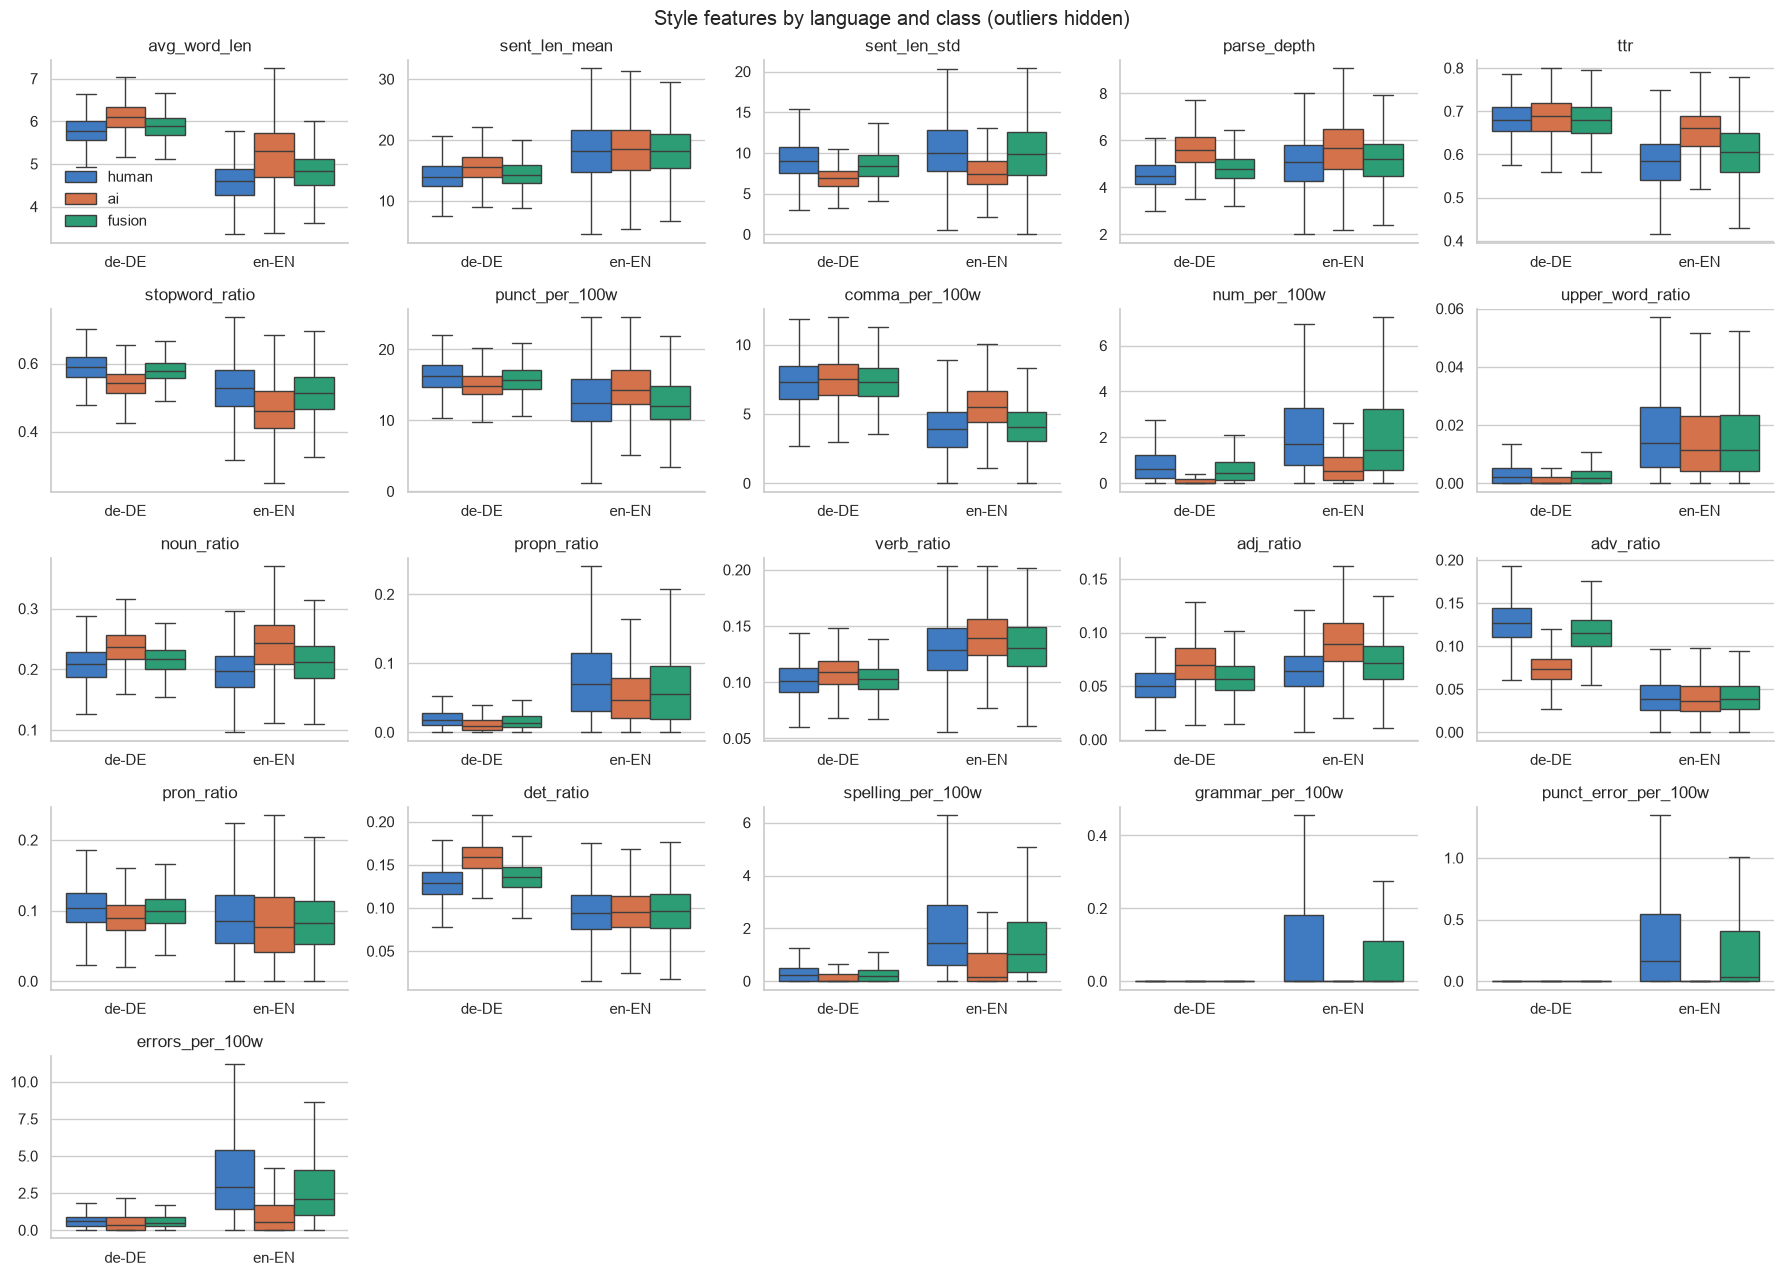

In [68]:
n_cols = 5
fig, axes = plt.subplots(int(np.ceil(len(FEATURES) / n_cols)), n_cols, figsize=(18, 13))
for ax, feat in zip(axes.flat, FEATURES):
    sns.boxplot(data=style, x="lang", y=feat, hue="label", hue_order=LABELS, palette=PALETTE,
                showfliers=False, ax=ax, legend="auto" if ax is axes.flat[0] else False)
    ax.set(title=feat, xlabel="", ylabel="")
for ax in axes.flat[len(FEATURES):]:
    ax.set_visible(False)
axes.flat[0].legend(title="", frameon=False)
fig.suptitle("Style features by language and class (outliers hidden)")
fig.tight_layout()
plt.show()

**How well does each feature alone separate fusion from human / ai?** One-feature AUC = probability that a random fusion text has a *higher* value than a random human (or ai) text.
- 0.5: the feature is useless (a coin flip). 1.0 or 0.0: it separates the two classes perfectly.
- Above 0.5: fusion tends to have more of it; below 0.5: fusion tends to have less. The further from 0.5, the more useful the feature.
- Rank-based, so it also works for skewed features with many zeros (numbers, error rates).

de-DE                        en-EN             
                     fusion vs human fusion vs ai fusion vs human fusion vs ai
avg_word_len                    0.58         0.32            0.65         0.30
sent_len_mean                   0.55         0.37            0.50         0.49
sent_len_std                    0.43         0.77            0.48         0.70
parse_depth                     0.63         0.22            0.53         0.39
ttr                             0.49         0.44            0.59         0.27
stopword_ratio                  0.42         0.76            0.44         0.68
punct_per_100w                  0.43         0.61            0.48         0.33
comma_per_100w                  0.50         0.47            0.54         0.27
num_per_100w                    0.42         0.78            0.47         0.70
upper_word_ratio                0.46         0.64            0.46         0.50
noun_ratio                      0.58         0.29            0.61         0.32
propn_ratio                     0.42         0.63            0.43         0.54
verb_ratio                      0.53         0.40            0.52         0.40
adj_ratio                       0.61         0.31            0.60         0.29
adv_ratio                       0.37         0.91            0.50         0.52
pron_ratio                      0.45         0.60            0.47         0.54
det_ratio                       0.60         0.20            0.52         0.51
spelling_per_100w               0.46         0.62            0.42         0.69
grammar_per_100w                0.54         0.46            0.47         0.61
punct_error_per_100w            0.50         0.48            0.45         0.65
errors_per_100w                 0.48         0.59            0.41         0.75

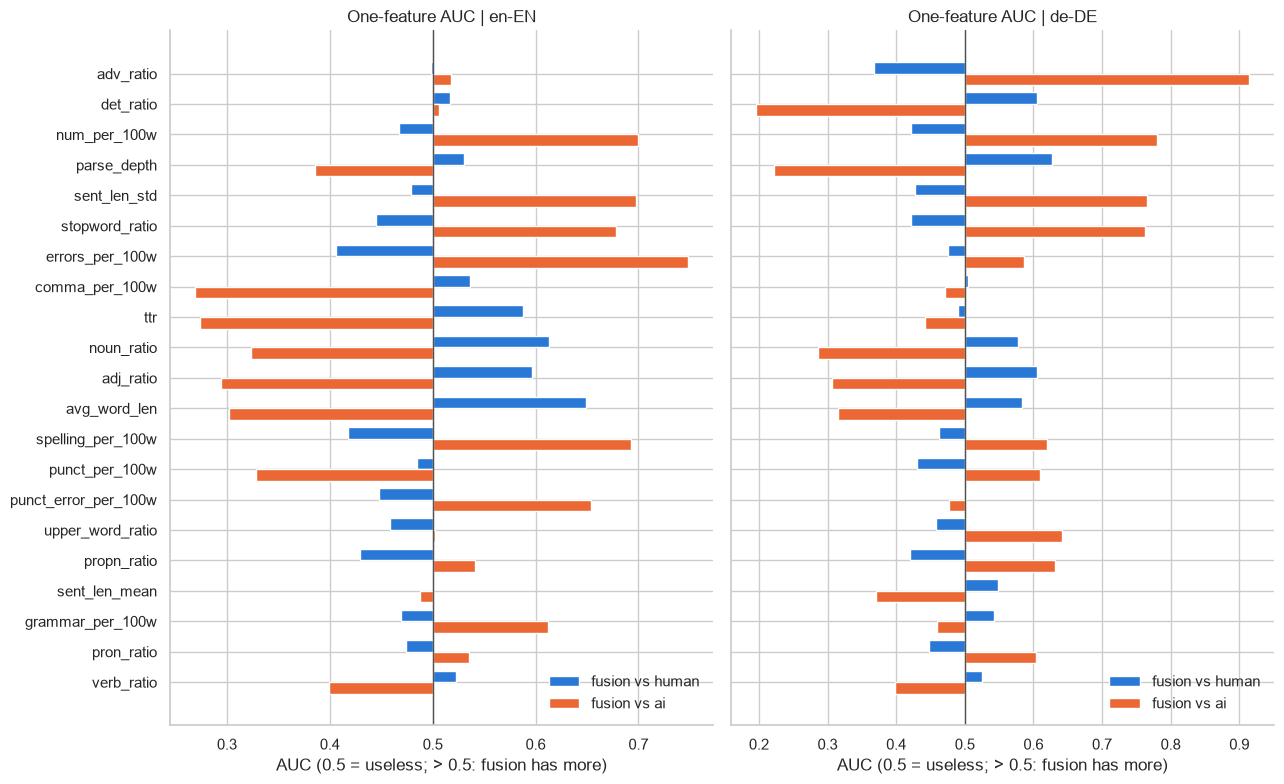

In [76]:
from sklearn.metrics import roc_auc_score


def feature_auc(df, other, target="fusion"):
    """P(random target text has a higher feature value than a random `other` text), per feature."""
    pair = df[df["label"].isin([target, other])]
    aucs = {}
    for feat in FEATURES:
        valid = pair[feat].notna()
        aucs[feat] = roc_auc_score(pair.loc[valid, "label"] == target, pair.loc[valid, feat])
    return pd.Series(aucs)


aucs = pd.concat({
    lang: pd.DataFrame({f"fusion vs {other}": feature_auc(g, other) for other in ["human", "ai"]})
    for lang, g in style.groupby("lang")
}, axis=1)
display(aucs.round(2))

# Bars start at 0.5 (useless), so their length shows how much a feature helps.
order = (aucs - 0.5).abs().max(axis=1).sort_values().index
y = np.arange(len(order))
height = 0.38
fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=True)
for ax, lang in zip(axes, langs):
    for k, other in enumerate(["human", "ai"]):
        values = aucs[(lang, f"fusion vs {other}")].loc[order]
        ax.barh(y + (0.5 - k) * height, values - 0.5, left=0.5, height=height,
                color=PALETTE[other], edgecolor="white", linewidth=1, label=f"fusion vs {other}")
    ax.axvline(0.5, color="#52514e", linewidth=1)
    ax.set_yticks(y, order)
    ax.set(title=f"One-feature AUC | {lang}", xlabel="AUC (0.5 = useless; > 0.5: fusion has more)")
    ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
plt.show()

**Notes: what makes fusion different**

Medians, human / fusion / ai:

| feature | English | German |
|---|---|---|
| `avg_word_len` | 4.61 / 4.84 / 5.29 | 5.78 / 5.88 / 6.09 |
| `sent_len_std` | 10.0 / 9.8 / 7.4 | 9.0 / 8.4 / 6.9 |
| `noun_ratio` | 0.197 / 0.213 / 0.243 | 0.209 / 0.216 / 0.236 |
| `num_per_100w` | 1.70 / 1.45 / 0.54 | 0.62 / 0.43 / 0.00 |
| `errors_per_100w` | 2.94 / 2.08 / 0.56 | 0.59 / 0.51 / 0.31 |
| `adv_ratio` | 0.039 / 0.039 / 0.037 | 0.127 / 0.116 / 0.073 |

- **Fusion sits between human and ai, much closer to human**, on almost every feature.
- **AI is the "smooth", formal class:** steadier sentence lengths, longer words, more nouns and adjectives, deeper parse trees, fewer stopwords. In English also more commas (5.5 vs 3.9 / 4.0 per 100 words) and a richer vocabulary (TTR 0.66 vs 0.59 / 0.61).
- **AI makes almost no errors:** LanguageTool flags 0.56 errors per 100 words in English ai vs 2.94 human / 2.08 fusion, mostly spelling (`TYPOS` = 62% of all matches). German texts have few errors in every class (0.3–0.6). Grammar and punctuation errors have a median of 0 in every group.
- **AI avoids numbers:** fusion keeps most of them → numbers and dates seem to survive the rewriting.
- **Fusion vs ai is easy with single features** (one-feature AUC):
  - German: `adv_ratio` 0.91, `num_per_100w` 0.78, `sent_len_std` 0.77, `stopword_ratio` 0.76 (fusion has more); `det_ratio` 0.20, `parse_depth` 0.22 (fusion has less).
  - English: `errors_per_100w` 0.75, `sent_len_std` 0.70, `num_per_100w` 0.70, `spelling_per_100w` 0.69 (fusion has more); `ttr` 0.27, `comma_per_100w` 0.27, `adj_ratio` 0.29, `avg_word_len` 0.30 (fusion has less).
- **Fusion vs human is weak:**
  - English: best are `avg_word_len` 0.65, `noun_ratio` 0.61, `adj_ratio` 0.60 (fusion has more) and `errors_per_100w` 0.41 (fusion has fewer); everything else is 0.42–0.59.
  - German: best are `parse_depth` 0.63, `adj_ratio` 0.61, `det_ratio` 0.60 and `adv_ratio` 0.37; everything else is 0.42–0.58.
- **To check:** the German adverb gap may be a `bundestag` speech effect: spaCy tags particles like `ja`, `doch`, `auch`, `noch` as ADV, and spoken human speeches use many of them.

**→ For modelling**
- Whole-text statistics separate fusion from ai, but not from human. Fusion vs human is the hard pair and will cause most errors. It needs richer signals (word / character n-grams, a transformer).
- Stylometric + error features are a cheap add-on to the baseline: a candidate "own approach" experiment.
- Fusion = human start + AI rest (section 5), so computing the features per chunk (start vs end) may separate fusion from human better than whole-text averages.

**Caveats**
- Samples: 30k texts for spaCy features, 10k for LanguageTool.
- AUCs pool all domains, and the domain mix differs by class (`arxiv_papers` / `gutenberg` are mostly ai), so some gaps may be domain effects.
- Each AUC looks at one feature alone; several weak features can still help together in a model.

## 5. Data quality

In [70]:
def quality_report(df):
    """Missing, empty and very short texts."""
    text = df["text"].fillna("")
    return pd.Series({
        "rows": len(df),
        "missing text": df["text"].isna().sum(),
        "empty / whitespace-only text": (text.str.strip() == "").sum(),
        "texts < 20 words": (df["n_words"] < 20).sum(),
        "missing lang or domain": df[["lang", "domain"]].isna().any(axis=1).sum(),
        "duplicate ids": df["id"].duplicated().sum(),
    })


display(pd.DataFrame({"train": quality_report(train), "test": quality_report(test)}))

# Shortest texts per class: very short texts carry little signal.
train.groupby("label")["n_words"].describe(percentiles=[0.01, 0.05])[["min", "1%", "5%"]].loc[LABELS]

,train,test
rows,272352,25000
missing text,0,0
empty / whitespace-only text,0,0
texts < 20 words,0,0
missing lang or domain,0,0
duplicate ids,0,0


,min,1%,5%
label,,,
human,20.0,26.0,57.0
ai,20.0,28.0,60.0
fusion,20.0,36.0,79.0


### Duplicates
Exact duplicates (same text) and near-duplicates (same first 200 characters). Near-duplicates with *different* labels would mean a human text and its fusion / ai rewrite are both in the data. Those must stay on the same side of the validation split.

In [71]:
train["text_hash"] = pd.util.hash_pandas_object(train["text"], index=False)
test_hash = pd.util.hash_pandas_object(test["text"], index=False)
dup = train[train["text_hash"].duplicated(keep=False)]

display(pd.Series({
    "train rows that are exact duplicates": len(dup),
    "exact-duplicate groups": dup["text_hash"].nunique(),
    "groups with conflicting labels": (dup.groupby("text_hash")["label"].nunique() > 1).sum(),
    "test texts that also appear in train": test_hash.isin(train["text_hash"]).sum(),
    "duplicate texts within test": test_hash.duplicated().sum(),
}, name="count").to_frame())

if len(dup):
    display(pd.crosstab(dup["domain"], dup["label"])[LABELS])

,count
train rows that are exact duplicates,0
exact-duplicate groups,0
groups with conflicting labels,0
test texts that also appear in train,0
duplicate texts within test,0


In [72]:
def prefix_key(texts, n=200):
    """Lower-cased first n characters with whitespace collapsed (catches near-duplicates)."""
    return texts.str[: 2 * n].str.lower().str.replace(r"\s+", " ", regex=True).str.strip().str[:n]


train["prefix"] = prefix_key(train["text"])
test_prefix = prefix_key(test["text"])

shared = train[train["prefix"].duplicated(keep=False)]
label_mix = shared.groupby("prefix")["label"].agg(lambda x: " + ".join(sorted(set(x))))
print(f"train texts sharing their first 200 characters with another train text: {len(shared):,}")
print(f"test texts sharing their first 200 characters with a train text: {test_prefix.isin(train['prefix']).sum():,}")
print(f"test texts sharing their first 200 characters with another test text: {test_prefix.duplicated(keep=False).sum():,}")
display(label_mix.value_counts().rename("prefix groups").to_frame())

# One example group with different labels (truncated).
mixed = label_mix[label_mix.str.contains(r"\+")]
if len(mixed):
    for _, row in train[train["prefix"] == mixed.index[0]].head(3).iterrows():
        print(f"--- {row['label'].upper()} | {row['domain']} | {row['n_words']} words")
        print(snippet(row["text"], 150), "\n")

train texts sharing their first 200 characters with another train text: 106,415
test texts sharing their first 200 characters with a train text: 0
test texts sharing their first 200 characters with another test text: 0


,prefix groups
label,
fusion + human,43077
fusion,811
ai,93
human,15
ai + fusion + human,1


--- FUSION | student_essays | 165 words
" A study last year found that driving by young people decreased 23 percent between 2001 and 2009". Limiting the use of cars from people is a great th [...] tes physical health. Cycling is an excellent form of exercise that strengthens muscles, improves cardiovascular health, and boosts overall well-being. 

--- HUMAN | student_essays | 249 words
" A study last year found that driving by young people decreased 23 percent between 2001 and 2009". Limiting the use of cars from people is a great th [...] ople wont have to drive cars. Cars cost a lot more money than a simple bicycle does. You also dont have to maintain a bicycle as much as you do a car. 



,% fusion texts with a human twin
domain,
bundestag,87.5
cnn_news,75.8
student_essays,74.8
euro_court_cases,74.5
blog_authorship_corpus,60.4
house_of_commons,59.4
arxiv_papers,28.2
gutenberg,0.3


fusion texts with a human twin: 60,554 of 83,682 (72%)


,copied words,human twin words,fusion words,share of twin copied
0.10,60.9,227.0,182.00,0.13
0.25,99.0,359.0,299.00,0.23
0.50,191.0,543.0,469.00,0.40
0.75,329.0,790.0,687.25,0.61
0.90,522.0,1162.1,1005.10,0.78


pairs where the copied part alone fills one 512-token window (> 350 words): 23%


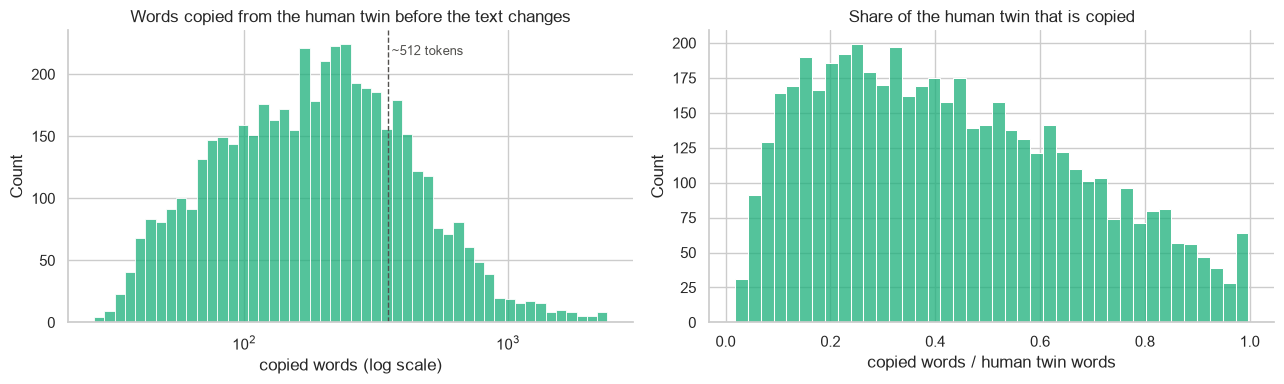

In [73]:
# Many fusion texts start exactly like a human text in train ("twins").
# How many have a twin, and for how many words does the fusion text copy its human twin?
WINDOW_WORDS = 350  # ~ one 510-token window at ~1.45 tokens per word (section 2)

human_by_prefix = train[train["label"] == "human"].drop_duplicates("prefix", keep=False).set_index("prefix")["text"]
fusion = train[train["label"] == "fusion"]
has_twin = fusion["prefix"].isin(human_by_prefix.index)
display((100 * has_twin.groupby(fusion["domain"]).mean()).round(1).sort_values(ascending=False)
        .rename("% fusion texts with a human twin").to_frame())
print(f"fusion texts with a human twin: {has_twin.sum():,} of {len(fusion):,} ({has_twin.mean():.0%})")


def copied_words(fusion_text, human_text):
    """Number of leading words the fusion text copies unchanged from its human twin."""
    return len(os.path.commonprefix([fusion_text.split(), human_text.split()]))


pairs = fusion[has_twin].sample(5_000, random_state=SEED)
twin_text = human_by_prefix.loc[pairs["prefix"]].to_numpy()
twin_len = np.array([len(t.split()) for t in twin_text])
twins = pd.DataFrame({
    "copied words": [copied_words(f, h) for f, h in zip(pairs["text"], twin_text)],
    "human twin words": twin_len,
    "fusion words": pairs["n_words"].to_numpy(),
})
twins["share of twin copied"] = twins["copied words"] / twins["human twin words"]
display(twins.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).round(2))
print(f"pairs where the copied part alone fills one 512-token window (> {WINDOW_WORDS} words): "
      f"{(twins['copied words'] > WINDOW_WORDS).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(twins["copied words"], log_scale=True, bins=50, color=PALETTE["fusion"], ax=axes[0])
axes[0].axvline(WINDOW_WORDS, color="#52514e", linestyle="--", linewidth=1)
axes[0].text(WINDOW_WORDS, axes[0].get_ylim()[1] * 0.95, " ~512 tokens", color="#52514e", fontsize=9, va="top")
axes[0].set(title="Words copied from the human twin before the text changes", xlabel="copied words (log scale)")
sns.histplot(twins["share of twin copied"], bins=40, color=PALETTE["fusion"], ax=axes[1])
axes[1].set(title="Share of the human twin that is copied", xlabel="copied words / human twin words")
fig.tight_layout()
plt.show()

#### Example twins
One human–fusion pair per domain from the 5k sample above, picked so that the split comes after 50–300 copied words. Grey = identical in both texts (the long middle is collapsed); **‖** = the first word where they differ; coloured = how each text continues.

In [77]:
import html
from IPython.display import HTML

START_WORDS = 15    # words shown from the shared start
CONTEXT_WORDS = 15  # shared words shown right before the texts diverge
AFTER_WORDS = 40    # words shown after the split point
GREY = "#8a8984"


def twin_html(row):
    """Shared start (grey) and the first words after the split (coloured) for one human-fusion pair."""
    words, n = row["text"].split(), row["copied"]
    if n > START_WORDS + CONTEXT_WORDS:
        skipped = f" <i>[… {n - START_WORDS - CONTEXT_WORDS} identical words …]</i> "
        shared = html.escape(" ".join(words[:START_WORDS])) + skipped + html.escape(" ".join(words[n - CONTEXT_WORDS:n]))
    else:
        shared = html.escape(" ".join(words[:n]))
    lines = []
    for label, text in [("human", row["twin"]), ("fusion", row["text"])]:
        rest = text.split()
        after = html.escape(" ".join(rest[n:n + AFTER_WORDS])) + (" …" if len(rest) > n + AFTER_WORDS else "")
        lines.append(f'<tr><td style="text-align:left; color:{PALETTE[label]}; vertical-align:top"><b>{label}</b><br>{len(rest)} words</td>'
                     f'<td style="text-align:left"><span style="color:{GREY}">{shared}</span> '
                     f'<span style="color:{PALETTE[label]}"><b>‖</b> {after}</span></td></tr>')
    header = f"<b>{row['domain']}</b>: first {n} words identical, then the texts diverge (‖)"
    return f"<p>{header}</p><table>{''.join(lines)}</table>"


# One pair per domain from the sampled twins above; split point between 50 and 300 words so both parts are visible.
examples = pairs.assign(copied=twins["copied words"].to_numpy(), twin=twin_text).query("50 <= copied <= 300")
for domain in ["cnn_news", "student_essays", "bundestag", "euro_court_cases"]:
    display(HTML(twin_html(examples[examples["domain"] == domain].sample(1, random_state=SEED).iloc[0])))

human930 words,"Elizabeth Starr fears her now illegal boob job will kill her after her breasts ballooned [… 154 identical words …] worrying I might be struck down by infections or blood clots - it's ruined my ‖ life.' Ms Starr, from Los Angeles, California, was already a 32F when she opted for the polypropylene string implants in 1999. The £3,000 procedure involved inserting synthetic string into the breasts to stimulate fluid production and growth. But just a …"
fusion573 words,"Elizabeth Starr fears her now illegal boob job will kill her after her breasts ballooned [… 154 identical words …] worrying I might be struck down by infections or blood clots - it's ruined my ‖ life. ' Ms Starr, from Los Angeles, California, was already a 32F when she opted for the polypropylene string implants in 1999. The £3,000 procedure involved inserting synthetic string into the breasts to stimulate fluid production and growth. But just …"


human178 words,"Can you imagine a world with free personal transportation? A world where there's not a [… 127 identical words …] are completely avoidable,and I think should make changes in technology to prevent occurences like that. ‖ All in all,I think that self driven cars are a positive innovation. I hope to see them on the road soon."
fusion179 words,"Can you imagine a world with free personal transportation? A world where there's not a [… 127 identical words …] are completely avoidable,and I think should make changes in technology to prevent occurences like that. ‖ While the idea of automatic cars offers convenience, it also raises concerns about safety, job displacement, and the loss of personal freedom."


human547 words,"Vielen Dank. – Sehr verehrte Frau Präsidentin! Liebe Kolleginnen und Kollegen! Ich möchte zu Beginn [… 202 identical words …] wo man noch etwas verbessern könnte. Das sollen sie auch; das ist ja ihre Aufgabe. ‖ Einen Wunsch, der mir auch sehr wichtig ist und den ich in der ersten Beratung hier im Plenum bereits erwähnt hatte, wollen wir gerne aufgreifen; das haben wir im Innenausschuss gestern auch so beschlossen. Es geht um eine statistische Erfassung …"
fusion544 words,"Vielen Dank. – Sehr verehrte Frau Präsidentin! Liebe Kolleginnen und Kollegen! Ich möchte zu Beginn [… 202 identical words …] wo man noch etwas verbessern könnte. Das sollen sie auch; das ist ja ihre Aufgabe. ‖ Genau genommen gehen wir mit diesem Gesetzentwurf einen wichtigen Schritt in Richtung mehr Rechtssicherheit für alle. Es schafft Klarheit, indem es die Vorgaben des Bundesverfassungsgerichts umsetzt und gleichzeitig den notwendigen Spielraum für die Sicherheitsbehörden erhalten bleibt. Wir müssen im Einklang …"


human139 words,"5. The applicant was born in 1937 and lived in Budapest. 6. On 23 April [… 52 identical words …] partial judgment on 25 June 2008 and remitted the case to the first instance court. ‖ 9. The case was terminated by the Budapest Regional Court on 1 December 2011 (service: 6 January 2012). 10. On 6 March 2012 the applicant’s lawyer posted a first communication to the Court, indicating an intention to lodge an application …"
fusion93 words,5. The applicant was born in 1937 and lived in Budapest. 6. On 23 April [… 52 identical words …] partial judgment on 25 June 2008 and remitted the case to the first instance court. ‖ ...5. The applicant was born in 1937 and lived in Budapest.6.


### Train vs test distribution shift
Test labels are unknown, so we can only compare language, domain and length.

In [74]:
TRAIN_COLOR, TEST_COLOR = "#8a8984", "#6250d6"


def share_compare(col):
    """Share (%) of each value in train vs test."""
    return pd.DataFrame({
        "train %": 100 * train[col].value_counts(normalize=True),
        "test %": 100 * test[col].value_counts(normalize=True),
    }).fillna(0).round(1).sort_values("train %", ascending=False).assign(
        **{"test / train": lambda d: (d["test %"] / d["train %"]).round(2)})


display(share_compare("lang"))
display(share_compare("domain"))

# Length: per language, because the language mix itself differs.
pd.concat({"train": length_table(train, "lang"), "test": length_table(test, "lang")}, axis=1)

,train %,test %,test / train
lang,,,
en-EN,80.6,85.3,1.06
de-DE,19.4,14.7,0.76


,train %,test %,test / train
domain,,,
student_essays,19.9,15.9,0.80
bundestag,19.2,14.3,0.74
cnn_news,16.3,19.7,1.21
blog_authorship_corpus,14.9,17.8,1.19
house_of_commons,11.7,11.8,1.01
euro_court_cases,10.1,6.4,0.63
arxiv_papers,5.2,6.7,1.29
gutenberg,2.7,7.4,2.74


train                    test                  
         p5 median   p90   p99   p5 median  p90   p99
lang                                                 
de-DE   111    512   829  1321   68    459  771  1335
en-EN    59    444  1018  2545   48    457  978  2354

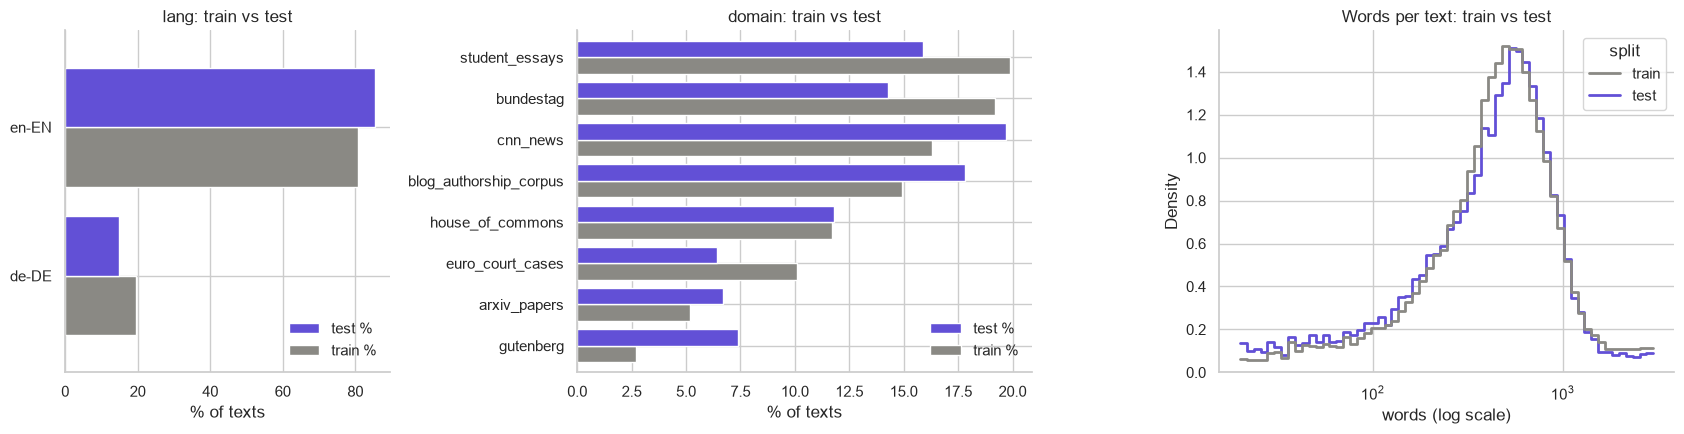

In [75]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
for ax, col in zip(axes, ["lang", "domain"]):
    share_compare(col)[["train %", "test %"]].iloc[::-1].plot.barh(
        ax=ax, color=[TRAIN_COLOR, TEST_COLOR], width=0.8, edgecolor="white", linewidth=1)
    handles, names = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], names[::-1], frameon=False, loc="lower right")
    ax.set(title=f"{col}: train vs test", xlabel="% of texts", ylabel="")

both = pd.concat([train[["n_words"]].assign(split="train"), test[["n_words"]].assign(split="test")])
sns.histplot(data=both, x="n_words", hue="split", palette={"train": TRAIN_COLOR, "test": TEST_COLOR},
             log_scale=True, element="step", fill=False, stat="density", common_norm=False,
             bins=60, linewidth=2, ax=axes[2])
axes[2].set(title="Words per text: train vs test", xlabel="words (log scale)")
fig.tight_layout()
plt.show()

**Notes: data quality**
- **Clean basics:** no missing or empty texts, no missing language / domain, no duplicate ids.
- **Minimum length filter:** the shortest text has exactly 20 words in every class. Fusion has fewer very short texts (1% quantile 36 words vs 26 human / 28 ai).
- **No exact duplicates:** none within train, none within test, none between train and test.
- **Human–fusion twins:** 72% of fusion texts (60,554) start exactly like a human text in train: `bundestag` 88%; `cnn_news`, `student_essays`, `euro_court_cases` ~75%; blogs, `house_of_commons` ~60%; `arxiv_papers` 28%; `gutenberg` 0.3%. AI texts never share an opening with human texts (1 group).
- **Fusion = human start + AI-written rest:** a fusion text copies its twin word for word for a median of 191 words (40% of the twin; 10–90%: 61–522 words), then changes. It is usually shorter than its twin (median 469 vs 543 words).
- **Head-only truncation hides the AI part:** in 23% of pairs the copied human part alone is longer than one 512-token window (~350 words), so a head-only model sees *only human text* for these fusion texts.
- **Test has no twins:** 0 test texts share their first 200 characters with a train text or with another test text.
- **Train vs test shift:**
  - Language: test has more English (85.3% vs 80.6%).
  - More common in test: `gutenberg` 2.7× (7.4% vs 2.7%), `arxiv_papers` 1.3×, `cnn_news` 1.2×, `blog_authorship_corpus` 1.2×.
  - Less common in test: `euro_court_cases` 0.63×, `bundestag` 0.74×, `student_essays` 0.80×.
  - Length per language is similar (median EN 444 vs 457 words, DE 512 vs 459).

**→ For modelling**
- Group the validation split by the 200-character prefix so each human–fusion pair stays on one side. A random split would put twins on both sides, which never happens in test.
- Prefer chunking or head + tail over head-only; it should matter most for fusion.
- `gutenberg` and `arxiv_papers` are mostly ai in train; if that holds in test, test has more ai than train. Report per-domain F1, and check whether results change when validation is weighted by the test domain mix.
- Idea: the twins show where the human text ends and the AI part starts, which could be used to train on the changed part only.

## 6. Fixed validation split
10 folds with `StratifiedGroupKFold` (seed 42): stratified by label × language, grouped by the 200-character prefix, so human–fusion twins always fall into the same fold (section 5).
- **Fold 0 is the fixed validation set** for every comparison (~27k texts, close to the 25k test size); folds 1–9 are training data.
- All fold numbers are saved, so cross-validation is possible later.
- Fit vectorizers, scalers and feature selection on the training folds only.

Usage in the other notebooks:
```python
folds = pd.read_csv("../splits/train_folds.csv")
train = train.merge(folds, on="id", validate="1:1")
trn, val = train[train["fold"] != 0], train[train["fold"] == 0]
```

In [78]:
from sklearn.model_selection import StratifiedGroupKFold

N_FOLDS = 10  # one fold ~ 27k texts, close to the test size (25k)
VAL_FOLD = 0  # the fixed validation fold used for every comparison
SPLIT_PATH = Path("../splits/train_folds.csv")

strata = train["label"] + "|" + train["lang"]  # same label x language shares in every fold
cv = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = np.full(len(train), -1)
for k, (_, idx) in enumerate(cv.split(train, strata, groups=train["prefix"])):  # twins share a prefix
    folds[idx] = k
train["fold"] = folds
train["fold"].value_counts().sort_index().rename("texts").to_frame().T

fold,0,1,2,3,4,5,6,7,8,9
texts,27236,27236,27236,27234,27235,27235,27235,27234,27236,27235


In [79]:
is_val = train["fold"] == VAL_FOLD
assert (train["fold"] >= 0).all(), "some rows have no fold"
assert train.groupby("prefix")["fold"].nunique().max() == 1, "a prefix group crosses folds"


def split_shares(col):
    """Share (%) of each value in the validation fold vs the training folds."""
    return pd.DataFrame({
        "val %": 100 * col[is_val].value_counts(normalize=True),
        "train %": 100 * col[~is_val].value_counts(normalize=True),
    }).round(2)


print(f"val (fold {VAL_FOLD}): {is_val.sum():,} texts | train (other folds): {(~is_val).sum():,} | "
      f"prefix groups crossing folds: 0")
display(pd.concat({"label x lang": split_shares(strata), "domain": split_shares(train["domain"])}))

SPLIT_PATH.parent.mkdir(exist_ok=True)
train[["id", "fold"]].to_csv(SPLIT_PATH, index=False)
print(f"saved {SPLIT_PATH} ({len(train):,} rows: id, fold)")

val (fold 0): 27,236 texts | train (other folds): 245,116 | prefix groups crossing folds: 0


val %  train %
label x lang ai|en-EN                37.31    37.31
             fusion|en-EN            24.14    24.14
             human|en-EN             19.17    19.17
             ai|de-DE                 7.47     7.47
             fusion|de-DE             6.58     6.58
             human|de-DE              5.33     5.33
domain       student_essays          20.16    19.83
             bundestag               19.19    19.22
             cnn_news                16.25    16.26
             blog_authorship_corpus  15.18    14.86
             house_of_commons        11.46    11.72
             euro_court_cases         9.92    10.15
             arxiv_papers             5.15     5.26
             gutenberg                2.68     2.70

saved ../splits/train_folds.csv (272,352 rows: id, fold)


## 7. Summary: what the EDA means for modelling

| # | Finding | Decision | Section |
|---|---|---|---|
| 1 | 72% of fusion texts have a human twin in train (same first 200 characters); test has no twins at all. | **Validation split:** fixed, seed 42, stratified by label × language, **grouped by the 200-character prefix** so twins never cross the split. Saved in `splits/train_folds.csv` (fold 0 = validation). Use it for every comparison. | 5, 6 |
| 2 | Classes are imbalanced (ai 45% · fusion 31% · human 25%); the metric is macro-F1. | Class weights; tune thresholds / class priors on validation for macro-F1. Always report per-class F1 and a confusion matrix. | 1 |
| 3 | Fusion vs human is the hard pair: no single style feature separates them (AUC 0.35–0.65). Fusion vs ai is easy. | Focus error analysis on fusion ↔ human confusions. | 4 |
| 4 | Most texts are longer than 512 tokens (EN 52–67%, DE 74–92%). Fusion starts with copied human text (median 191 words; in 23% of pairs longer than one window). | Reference: head-only 512 tokens. Experiments: head + tail, chunking with averaged chunk predictions. Expect the biggest gain on fusion. | 2, 5 |
| 5 | Language ≈ domain (German = `bundestag`); `arxiv_papers` / `gutenberg` are 84–92% ai; test has a different domain mix (`gutenberg` 2.7×, `euro_court_cases` 0.63×). | Report per-language and per-domain F1. Check validation weighted by the test domain mix. Watch for domain shortcuts. | 1, 5 |
| 6 | Human texts keep artefacts, typos, casing quirks; AI makes ~5× fewer errors (EN 0.56 vs 2.94 per 100 words). | **No text cleaning:** keep case, punctuation, typos, `...`. Use character n-grams in the TF-IDF baseline. | 3, 4 |
| 7 | spaCy / LanguageTool features separate fusion from ai, and give weak signals against human. | Experiment: add style + error features to the baseline or an ensemble; try computing them per chunk (start vs end). | 4 |
| 8 | Length nearly separates ai in a few domains, but not fusion from human. | Use length only as an extra feature in experiments, checked per domain. | 2 |

**Open questions to check**
- Does fusion change style *within* a text (start vs end) while human texts do not?
- Are artefacts like `(CNN)`, `By .`, leading `...` class signals or only domain markers?
- Is the German adverb gap (AUC 0.91 fusion vs ai) a `bundestag` speech effect?
- About 6% of twin split points are only spacing differences (e.g. `life.'` vs `life. '`), so the copied-length numbers are slight underestimates (median ~209 words ignoring whitespace).

Fixed samples used above (seed 42): 20k texts for tokens, 30k for spaCy features, 10k for LanguageTool, 5k twin pairs.